In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection, Poly3DCollection
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim

from tqdm import tqdm

import copy

plt.rcParams["axes3d.mouserotationstyle"] = "azel"

In [76]:
def setdiff1d_t(t1, t2):
    mask = ~torch.isin(t1, t2)
    return t1[mask]


class MeshData:
    """
    Class containing mesh information for FDM
        - n_nodes: Number of nodes
        - n_edges: Number of edges
        - C: Connectivity matrix
        - X: Original node locations
        - free_ind: indices of free nodes
        - fixed_ind: indices of fixed nodes
    """

    def __init__(self, n=3, x_space=0.5, y_space=0.5):
        """
        - Generate the connectivity + data for a shell on an nxn grid.
        - All of the edges around the border are supports.
        - Units are m and kN.

        inputs:
            - n: side length of the generated square mesh
            - x_space: distance (in m) between nodes along the x-axis
            - y_space: distance (in m) between nodes along the y-axis

        outputs:
            - n_nodes: number of nodes in the mesh
            - n_edges: number of edges in the mesh
            - C: n_edges x n_nodes connectivity matrix
                If there is an edge i from node k to node m, then row i contains
                -1 in column k and 1 in column m. The graph is undirected, so the
                choice of which column to assign to -1 is arbitrary.
            - X: n_nodes x 3 original node positions matrix
            - free_ind: vector of indices of free nodes
            - fixed_ind: vector of indices of fixed nodes
        """

        self.n_nodes = n**2
        self.n_edges = 2 * (n - 1) * n

        # create mesh

        xs = torch.linspace(0, x_space * (n - 1), n)
        ys = torch.linspace(0, y_space * (n - 1), n)

        xv, yv = torch.meshgrid(xs, ys)

        # original position vector
        # save non-support positions as well so we can preview the mesh
        self.X = torch.column_stack((xv.ravel(), yv.ravel(), torch.zeros(n**2)))

        # create connectivity matrix
        self.C = torch.zeros((self.n_edges, self.n_nodes))

        edge_ctr = 0
        for node_ind in range(self.n_nodes):
            # if node_ind + 1 is a multiple of n, node_ind is at the end of a row
            # and doesn't have a neighbor to the right so we skip

            if (node_ind + 1) % n != 0 and node_ind + 1 < self.n_nodes:
                # print(f"Adding edge {edge_ctr} from node {node_ind}")
                self.C[edge_ctr, node_ind] = -1
                self.C[edge_ctr, node_ind + 1] = 1
                edge_ctr += 1

            # if the ind of the node above is out of range, skip

            if node_ind + n < self.n_nodes:
                # print(f"Adding edge {edge_ctr} from node {node_ind}")
                self.C[edge_ctr, node_ind] = -1
                self.C[edge_ctr, node_ind + n] = 1
                edge_ctr += 1

        # fixed indices are all of those along the outer boundary
        fixed_ind = [
            ind
            for ind in range(self.n_nodes)
            if (
                (ind - n < 0)
                or (ind + n >= self.n_nodes)
                or (ind % n == 0)
                or ((ind + 1) % n == 0)
            )
        ]

        self.fixed_ind = torch.tensor(fixed_ind)
        self.n_fixed = len(self.fixed_ind)

        all_ind = torch.tensor(range(self.n_nodes))
        self.free_ind = setdiff1d_t(all_ind, self.fixed_ind)
        self.n_free = len(self.free_ind)

        self.is_fixed = torch.zeros(self.n_nodes)
        self.is_fixed[self.fixed_ind] = 1.0

        self.Cn = self.C[:, self.free_ind]
        self.Cf = self.C[:, self.fixed_ind]

        self.Xf = self.X[self.fixed_ind, :]

    def eq_shape(self, q_vec, p_mat):
        """
        The governing equation of the force density method is
        C_n.T @ Q @ C_n @ X_n + C_n.T @ Q @ C_f @ X_f + p = 0.

        Solves for the equilibrium shape given an input force density
        vector and load matrix.

        Positive force densities represent compression.

        Differentiable by torch.

        inputs:
            - mesh_data: dictionary containing mesh data from
                generate_mesh_and_connectivity()
                * Derivatives wrt mesh_data not required
                    because it doesn't change
                    (I think)

            - q_vec: 1 x n_edges tensor containing force densities.
                Requires grad

            - p_mat: n_free x 3 tensor containing nodal loads.
                Doesn't require grad bc loading is imposed, not solved for

        outputs:
            - X_eq
        """

        Q = torch.diag(q_vec)

        # print(f"{self.Cn=}")
        # print(f"{Q=}")

        Dn = self.Cn.T @ Q @ self.Cn
        Df = self.Cn.T @ Q @ self.Cf

        X_free_eq = torch.linalg.solve(Dn, -p_mat - Df @ self.Xf)

        X_eq = self.X.clone().detach()
        X_eq[self.free_ind, :] = X_free_eq

        return X_eq

In [77]:
mesh_data = MeshData(
    n=5,
)

q_vec = torch.ones(mesh_data.n_edges, requires_grad=True) * 10
p_mat = torch.column_stack(
    (
        torch.zeros(mesh_data.n_free),
        torch.zeros(mesh_data.n_free),
        torch.ones(mesh_data.n_free) * -4,
    )
)

X_eq = mesh_data.eq_shape(
    q_vec,
    p_mat,
)

In [121]:
def visualize_mesh(mesh_data, X_eq=None):
    """
    Plots the mesh from mesh_data
    """

    %matplotlib qt

    if X_eq is not None:
        X = X_eq.detach().numpy()
    else:
        X = mesh_data["X"].numpy()

    n_edges = mesh_data.n_edges
    C = mesh_data.C.numpy()
    n = int(np.sqrt(mesh_data.n_nodes))

    edge_inds = [np.where(C[i, :])[0] for i in range(n_edges)]

    fig, ax = plt.subplots(
        1, 1, figsize=(8, 6), dpi=100, subplot_kw={"projection": "3d"}
    )

    segments = [X[edge, :] for edge in edge_inds]

    lc = Line3DCollection(
        segments,
        colors="blue",
        linewidths=0.5,
    )

    ax.add_collection(lc)

    faces = []
    for i in range(n - 1):
        for j in range(n - 1):
            faces.append(
                (i * n + j, (i + 1) * n + j, (i + 1) * n + (j + 1), i * n + (j + 1))
            )

    face_locs = [X[face, :] for face in faces]

    mesh = Poly3DCollection(
        face_locs,
        facecolor=(0.3, 0.5, 0.8, 0.3),
        edgecolor="none",
    )

    ax.add_collection(mesh)

    nodes = ax.scatter(
        X[:, 0],
        X[:, 1],
        X[:, 2],
        s=10,
        c="black",
    )

    fig.tight_layout()
    plt.show()


visualize_mesh(mesh_data, X_eq)

In [79]:
class FixedTopologySampleGenerator:
    """
    - Takes in a specific topology, represented by a MeshData object.
    - Generates samples with varying or constant load and force densities.
    - Saves the resulting shape-load to force-density correspondence
        that the PINN is supposed to learn.
    - Each node has feature vector [x_goal, y_goal, z_goal, is_boundary, p_x, p_y, p_z]
        Feature vectors are concatenated into a 1 x (n_nodes * 7) tensor
    """

    def __init__(
        self,
        mesh_data: MeshData,
        randomize_q=True,
        randomize_p=False,
        q_range=(0.5, 30),  # range of q-values. positive for now...
        p_range=(
            (0, 0),  # range of x loads
            (0, 0),  # range of y loads
            (-4, 0),  # range of z loads
        ),
    ):
        self.topology = mesh_data
        self.randomize_q = randomize_q
        self.randomize_p = randomize_p

        self.q_range = q_range
        self.p_range = p_range

    def sample(
        self,
        n=2,
        q_vec=None,
        p_mat=None,
    ):
        """
        Create training data: nodal feature vectors and force densities for
        randomized shells on the same topology.
        """

        samples = []
        qs = []

        for i in range(n):
            if self.randomize_q or (q_vec is None):
                # generate random force densities

                q_vec = (
                    torch.rand(self.topology.n_edges)
                    * (self.q_range[1] - self.q_range[0])
                    + self.q_range[0]
                )

            qs.append(q_vec)

            if self.randomize_p or (p_mat is None):
                # generate random loads

                px_vec = (
                    torch.rand(self.topology.n_free)
                    * (self.p_range[0][1] - self.p_range[0][0])
                    + self.p_range[0][0]
                )

                py_vec = (
                    torch.rand(self.topology.n_free)
                    * (self.p_range[1][1] - self.p_range[1][0])
                    + self.p_range[1][0]
                )

                pz_vec = (
                    torch.rand(self.topology.n_free)
                    * (self.p_range[2][1] - self.p_range[2][0])
                    + self.p_range[2][0]
                )

                p_mat = torch.column_stack((px_vec, py_vec, pz_vec))

            # print(f"{q_vec=}")

            # print(f"{p_mat=}")

            X_eq = mesh_data.eq_shape(
                q_vec,
                p_mat,
            )

            distance_scale = float(torch.max(X_eq))

            X_eq = X_eq / torch.max(X_eq)

            # print(f"{X_eq=}")

            sample_features = torch.column_stack(
                (X_eq, self.topology.is_fixed, torch.zeros((self.topology.n_nodes, 3)))
            )

            sample_features[self.topology.free_ind, 4:] = p_mat

            # print(f"{sample_features=}")

            samples.append(sample_features)

        sample_tensor = torch.stack(samples)  # n_samples x n_nodes x 7 (# features)
        q_tensor = torch.stack(qs)  # n_samples x n_edges

        return sample_tensor, q_tensor, distance_scale

In [80]:
sampler = FixedTopologySampleGenerator(
    mesh_data,
)

sample_tensor, q_tensor, distance_scale = sampler.sample(8)

torch.save(
    {
        "sample_tensor": sample_tensor,
        "q_tensor": q_tensor,
        "distance_scale": distance_scale,
    },
    "training data/8_batches_train.pt",
)

In [114]:
class ForceDensityPredictorPINN(nn.Module):
    """
    Multiple hidden layer neural network for any-D input/output
    """

    def __init__(
        self,
        topology,
        act_fn=nn.Tanh(),
        hidden_sizes=(10, 10),
        min_q=0.5,
        max_q=30,
    ):
        super(ForceDensityPredictorPINN, self).__init__()

        act_fn = act_fn
        layers = []
        prev_size = topology.n_nodes * 7

        for size in hidden_sizes:
            layer = nn.Linear(prev_size, size)

            nn.init.xavier_normal_(layer.weight)
            nn.init.zeros_(layer.bias)

            layers.append(layer)
            layers.append(act_fn)

            prev_size = size

        final_layer = nn.Linear(prev_size, topology.n_edges)
        nn.init.xavier_normal_(final_layer.weight)
        nn.init.zeros_(final_layer.bias)

        layers.append(final_layer)

        self.net = nn.Sequential(*layers)

        self.topology = topology

        self.min_q = torch.tensor(min_q)
        self.max_q = torch.tensor(max_q)

    def forward(self, x):
        # Forward pass
        z = self.net(x)
        z = torch.clamp(z, float(np.log(self.max_q)))
        return self.min_q + torch.exp(z)

In [ ]:
def pointwise_Lp_loss(
    model,
    Xs_train,
    distance_scale,
    p=2,
):
    """
    Computes a pointwise L^p shape norm between the goal
    nodal locations and the nodal locations caused by the trial
    force densities.

    This loss function can only be used when the goal shape and
    trial topology are exactly the same because it compares
    nodes with the same index.
    """

    loss = 0.0
    n_samples = Xs_train.shape[0]

    for batch_ind in range(n_samples):
        target_X = Xs_train[batch_ind, :, 0:3] * distance_scale
        p_mat = Xs_train[batch_ind, model.topology.free_ind, 4:]

        trial_q = model(Xs_train[batch_ind, :, :].flatten())

        hat_X = model.topology.eq_shape(
            trial_q,
            p_mat,
        )

        loss += torch.sum(torch.abs(hat_X - target_X) ** p)

    return loss / n_samples

In [98]:
# define some classes for different types of weighting


class LossWeighting:
    """base class with fixed weights"""

    def __init__(self, lambda_data=1.0, lambda_physics=1.0, lambda_bcs=1.0):
        self.lambda_data = lambda_data
        self.lambda_physics = lambda_physics
        self.lambda_bcs = lambda_bcs

    def __call__(self, loss_data, loss_physics, loss_bcs, model=None):
        return self.lambda_data, self.lambda_physics, self.lambda_bcs

    def zero_grad(self):
        pass

    def step(self):
        pass


class RelativeWeighting(LossWeighting):
    """Weights higher losses more"""

    def __call__(self, loss_data, loss_physics, loss_bcs, model=None):
        ld, lp, lb = (
            loss_data.detach(),
            loss_physics.detach(),
            loss_bcs.detach(),
        )  # treat weights as constants
        total = ld + lp + lb

        return ld / total, lp / total, lb / total


class SigmoidWeighting(LossWeighting):
    """Self-adaptive weights, w = sigmoid(lambda), lambdas trained by gradient ascent"""

    def __init__(self, lambda_data=1.0, lambda_physics=1.0, lambda_bcs=1.0, lr=1e-3):
        self.lambdas = torch.tensor(
            [lambda_data, lambda_physics, lambda_bcs], requires_grad=True
        )
        self.optimizer = optim.SGD([self.lambdas], lr=lr, maximize=True)

    def __call__(self, loss_data, loss_physics, loss_bcs, model=None):
        w = torch.sigmoid(self.lambdas)
        return w[0], w[1], w[2]

    def zero_grad(self):
        self.optimizer.zero_grad()

    def step(self):
        self.optimizer.step()


def train_pinn_adaptive(
    model,
    data_loss_fn,
    x_train,
    # y_train,
    data_loss_parameters=(),
    physics_loss_fn=lambda m, t: torch.zeros(()),
    t_colloc=None,
    physics_loss_parameters=(),
    bc_loss_fn=lambda m, x, u: torch.zeros(()),
    t_bc=None,
    u_bc=None,
    epochs=10000,
    lr=1e-3,
    weighting=None,
    data_start=0,
):
    """
    Train a physics-informed neural network with physics and boundary condition loss
    Weights are adaptive
    No training data

    Args:
        model: Neural network
        t_colloc: Collocation points for physics
        t_bc: Boundary condition points
        physics_loss, bc_loss: loss functions to use for physics and bcs
        physics_loss_parameters: parameters passed to physics_loss()
            q: function of x that returns the heat source at a location x
            kappa: system parameter
        lambda_physics, lambda_bcs: balance parameters
    """
    weighting = weighting or LossWeighting()

    # choose optimizer
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {
        "data": [],
        "physics": [],
        "bcs": [],
        "total": [],
        "data_weight": [],
        "physics_weight": [],
        "bcs_weight": [],
        "best_state": None,
        "best_metric": float("inf"),
        "best_epoch": 0,
    }

    pbar = tqdm(range(epochs), desc="Training PINN")
    for epoch in pbar:
        optimizer.zero_grad()
        weighting.zero_grad()

        # calculate data loss
        if x_train is None:
            loss_data = torch.tensor(0)
        else:
            loss_data = data_loss_fn(model, x_train, *data_loss_parameters)

        # calculate physics loss
        loss_physics = physics_loss_fn(model, t_colloc, *physics_loss_parameters)

        # calculate BC loss
        loss_bcs = bc_loss_fn(model, t_bc, u_bc)

        # get weights
        w_data, w_physics, w_bcs = weighting(loss_data, loss_physics, loss_bcs, model)

        history["data_weight"].append(float(w_data))
        history["physics_weight"].append(float(w_physics))
        history["bcs_weight"].append(float(w_bcs))

        # calculate total loss
        if epoch < data_start:
            total_loss = (
                (w_data + w_physics + w_bcs)
                / (w_data + w_bcs)
                * (w_data * loss_data + w_bcs * loss_bcs)
            )
        else:
            total_loss = (
                w_data * loss_data + w_physics * loss_physics + w_bcs * loss_bcs
            )

        # backpropagation
        total_loss.backward()
        optimizer.step()
        weighting.step()

        # get an unweighted metric to compare losses
        metric = loss_data.item() + loss_physics.item() + loss_bcs.item()
        if epoch >= data_start and metric < history["best_metric"]:
            history["best_metric"] = metric
            history["best_epoch"] = epoch
            history["best_state"] = copy.deepcopy(model.state_dict())

        # store losses
        history["data"].append(loss_data.item())
        history["physics"].append(loss_physics.item())
        history["bcs"].append(loss_bcs.item())
        history["total"].append(total_loss.item())

        # and weights

        # log
        if (epoch + 1) % 2000 == 0:
            pbar.set_postfix(
                {
                    "Data": f"{loss_data.item():0.6f}",
                    "Physics": f"{loss_physics.item():0.6f}",
                    "BCs": f"{loss_bcs.item():0.6f}",
                    "Total": f"{total_loss.item():0.6f}",
                }
            )

    return history

In [ ]:
topology = MeshData(n=5)

sampler = FixedTopologySampleGenerator(topology)

Xs_train, qs_train, distance_scale = sampler.sample(8)

model = ForceDensityPredictorPINN(
    topology=topology,
    hidden_sizes=(256, 256),
    min_q=0.5,
    max_q=30,
)

trial = pointwise_Lp_loss(model, Xs_train, distance_scale, p=2)

print(trial)

In [100]:
history = train_pinn_adaptive(
    model=model,
    data_loss_fn=pointwise_Lp_loss,
    x_train=Xs_train,
    data_loss_parameters=(distance_scale, 2),
)

Training PINN:   0%|          | 0/10000 [00:00<?, ?it/s]/var/folders/r1/w7qlg93554jbxxjgn8qx6x_40000gn/T/ipykernel_5127/179703986.py:48: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  z = torch.clamp(z, max=np.log(self.max_q))
Training PINN: 100%|██████████| 10000/10000 [00:49<00:00, 200.86it/s, Data=0.006048, Physics=0.000000, BCs=0.000000, Total=0.006048]


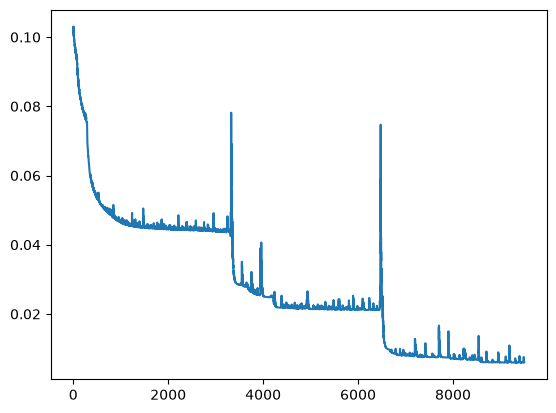

In [113]:
%matplotlib inline

plt.plot(history["data"][500:])